# 02 — Yearly envelope and peak regression

Daily aggregation, `scipy.signal.find_peaks`, and a UnivariateSpline fit to the upper envelope of generation.

The four-site plots below were produced from proprietary Powerverse data that is **not** in this public repository. Place `data/real/validation_Data.csv` locally to reproduce those figures. Without it, the notebook falls back to `data/synthetic/sample_site_0.csv` (one clear-sky site, so the 2x2 site grid will be sparse).

Section (iii) — feature extraction from the envelope — was not completed.


This code is used to make yearly data process including:

i) raw data process

1) integration of daily data 
2) find maximum daily power?(maybe not necessary as we already have the power of each sampling point)

ii) 
1) algorithm to find a regression curve of maximum
2) find the curve of the each sampling point

iii) post-process to find features from the curve

In [2]:
# Initialise library
import pandas as pd
import numpy as np


In [9]:
# Prefer local proprietary real data if present; otherwise use the public synthetic sample.
from pathlib import Path

real_path = Path('../data/real/validation_Data.csv')
synth_path = Path('../data/synthetic/sample_site_0.csv')
file_path = real_path if real_path.exists() else synth_path
print('Using', file_path)

df_real = pd.read_csv(file_path)

# Display the first few rows to inspect the data
print("Preview of validation_Data.csv:")
print(df_real.head())
# Check basic information about the dataset
print(f"Number of rows: {df_real.shape[0]}")
print(f"Number of columns: {df_real.shape[1]}")
# Check for any NA values in the dataset
print("\nChecking for NA values in the dataset:")
print(df_real.isna().sum())

Preview redacted in the public snapshot (proprietary site coordinates).
See the markdown banner: place data/real/validation_Data.csv locally to reproduce.


**From above info, we can see in solar_gen kwh, there are 4118 non-available sampling data which also need to be substituded by interpolation or other method**

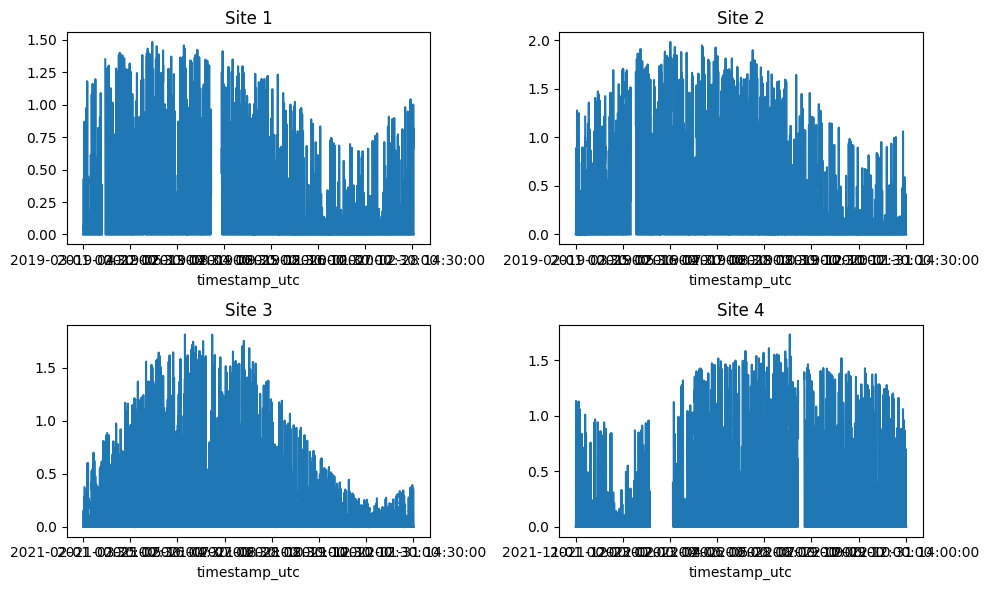

In [3]:
# split and plot 4 sites raw data
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes = axes.ravel()

for i, (site_id, group) in enumerate(df_real.groupby('site_id')):
    group.plot(x='timestamp_utc', y='solar_gen_kwh', title=f"Site {site_id}", legend=False, ax=axes[i])

plt.tight_layout()
plt.show()

## i) Raw data process section
try to fill cell below:

In [4]:
#  optional 
# fill-in the na data

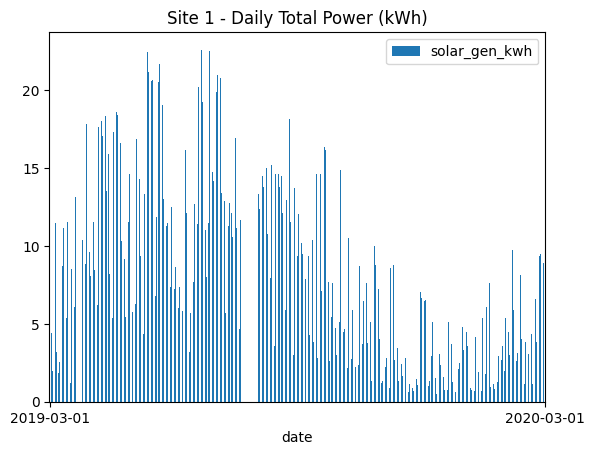

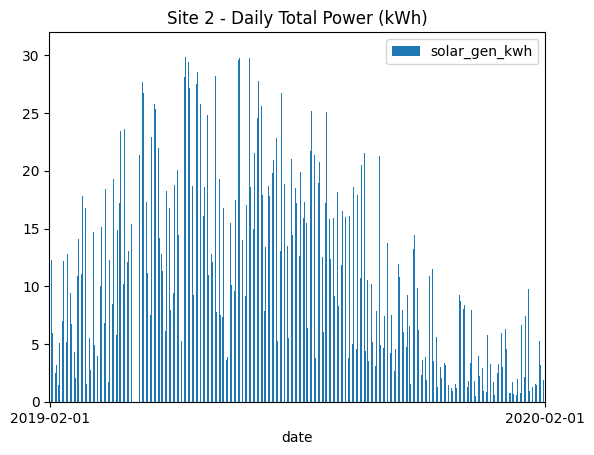

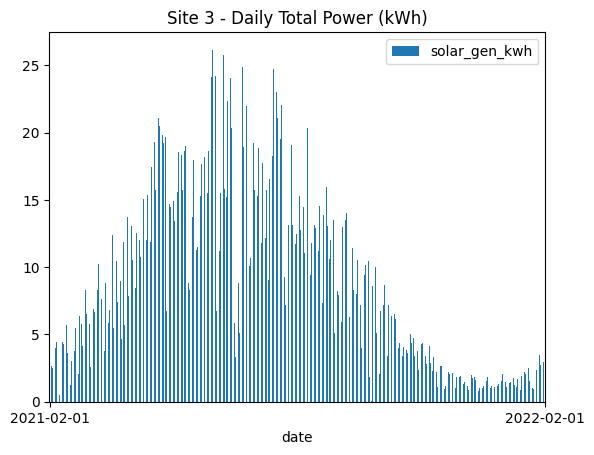

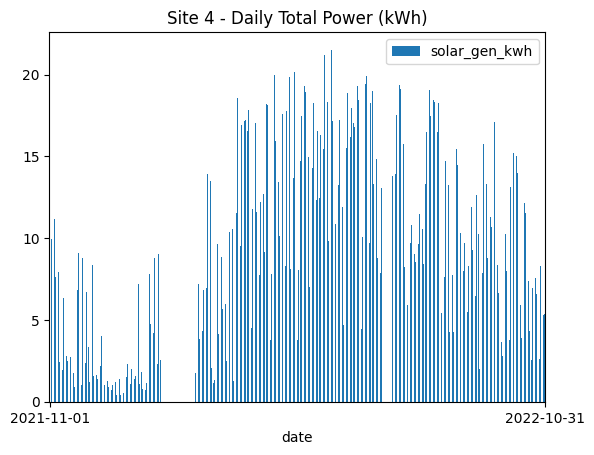

In [5]:
# Integration of daily data

# Convert the 'timestamp_utc' column to a datetime object, then extract only the date
df_real['date'] = pd.to_datetime(df_real['timestamp_utc']).dt.date

# Aggregate daily total power generation by site and date
daily_totals = df_real.groupby(['site_id', 'date'], as_index=False)['solar_gen_kwh'].sum()

# .sum function is applied to obtain a linear integration, which might not be accurate. 

# Plot daily total power for each site separately
for s_id, grp in daily_totals.groupby('site_id'):
    ax = grp.plot(
        x='date',
        y='solar_gen_kwh',
        kind='bar',
        title=f"Site {s_id} - Daily Total Power (kWh)",
        rot=0
    )
    ax.set_xticks([0, len(grp) - 1])  # Use only first and last dates as x-axis labels
    ax.set_xticklabels([grp['date'].iloc[0], grp['date'].iloc[-1]])
    plt.show()

**integrated power data is saved in**  *daily_totals* df


## ii) Algorithm to find a regression curve of maximum


Smooth method for the total daily data

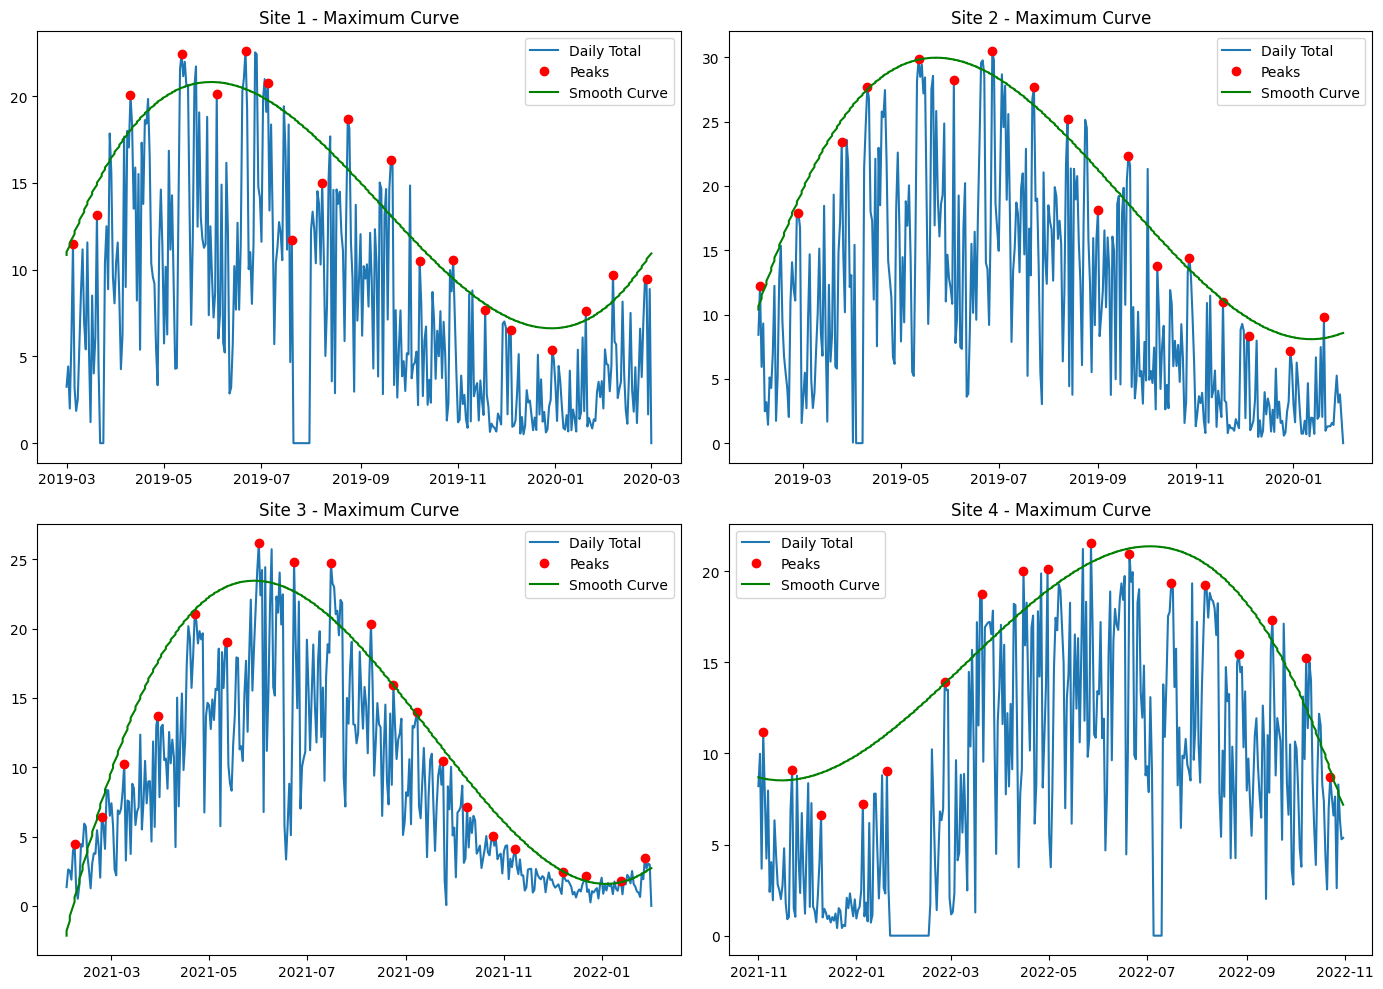

In [6]:
from scipy.interpolate import UnivariateSpline
from scipy.signal import find_peaks
# for daily_totals, apply find peak to plot maximum curve
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, (site_id, grp) in enumerate(daily_totals.groupby('site_id')):
    grp_sorted = grp.sort_values(by='date')
    y_values = grp_sorted['solar_gen_kwh'].values
    x_values = np.arange(len(y_values))

    # Find peaks
    peaks, _ = find_peaks(y_values, distance=14)  # Assuming a minimum distance of x days between peaks,7 is default
    # Yifei: I recomment play around with this distance, to check the factor affect. I recomment 35 could be a good value
    peak_values = y_values[peaks]
    peak_dates_num = x_values[peaks]

    # Fit a spline to the peak values
    spline = UnivariateSpline(peak_dates_num, peak_values, s=100.5)  # s is the smoothing factor, 0.5 is default

    smooth_dates_num = np.linspace(0, len(y_values) - 1, 500)  # Generate 500 points for a smooth curve
    smooth_values = spline(smooth_dates_num)

    # Plot the original data, peaks, and the smooth curve
    ax = axes[i]
    ax.plot(grp_sorted['date'], y_values, label='Daily Total')
    ax.plot(grp_sorted['date'].iloc[peaks], peak_values, 'ro', label='Peaks')
    ax.plot(grp_sorted['date'].iloc[smooth_dates_num.astype(int)], smooth_values, 'g-', label='Smooth Curve')
    ax.set_title(f"Site {site_id} - Maximum Curve")
    ax.legend()

plt.tight_layout()
plt.show()


In [7]:
#Nguyen and Bharat found these parameter values best suit the regression curves for maximum daily power
#site 1: distance = 21, s=100.5
#site 2: distance = 28, s=5
#site 3: distance = 21, s=5
#site 4: distance = 28, s=10


for the each sampling point

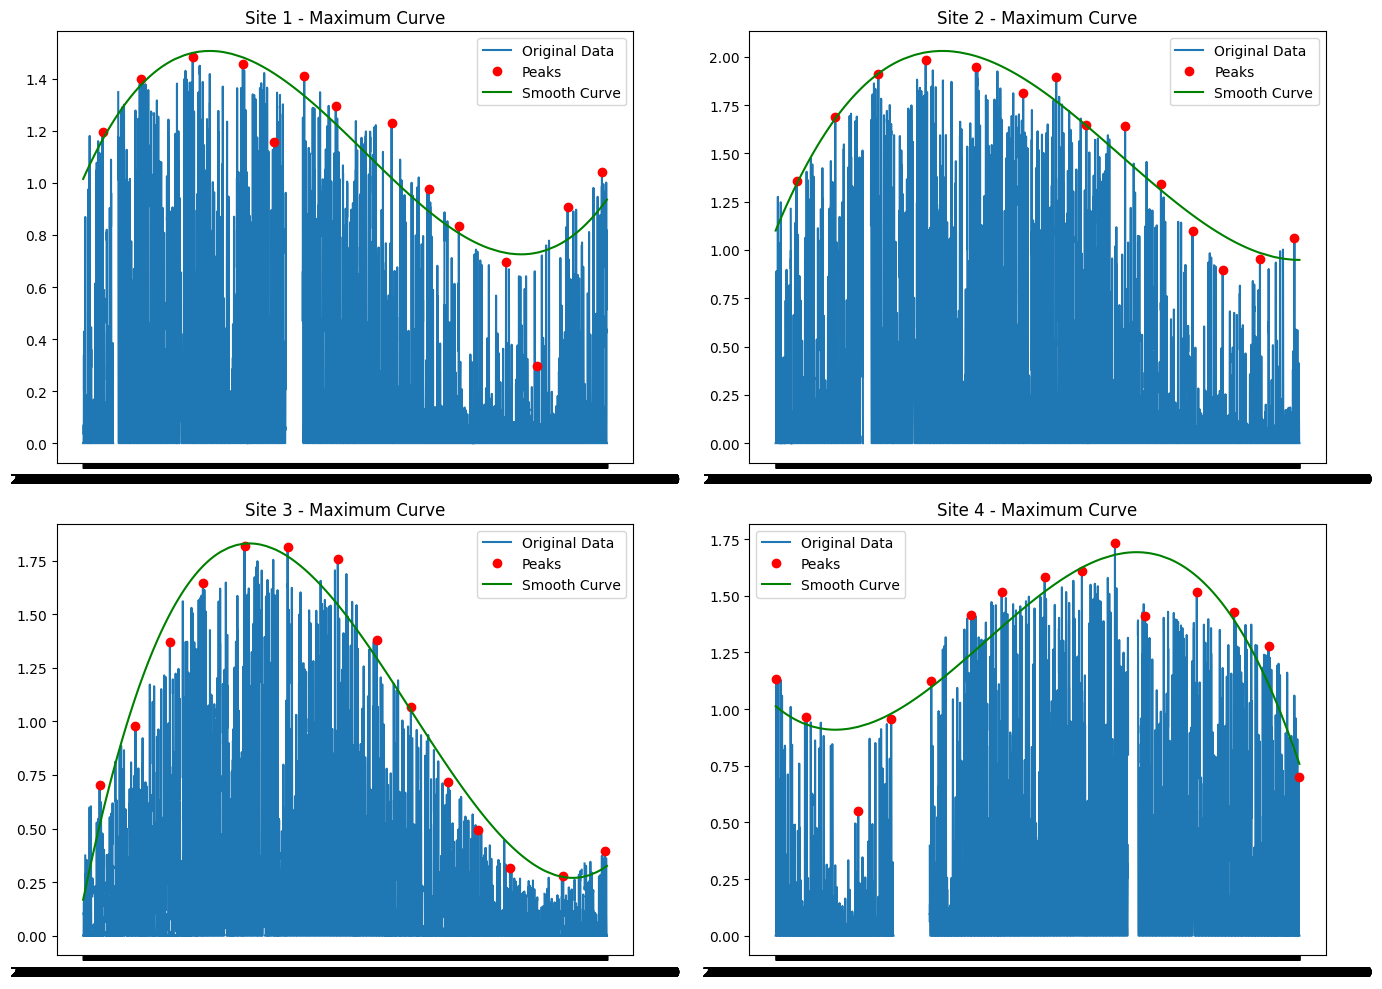

In [8]:
# for df_real, apply find peak to plot maximum curve
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, (site_id, grp) in enumerate(df_real.groupby('site_id')):
    grp_sorted = grp.sort_values(by='timestamp_utc')
    y_values = grp_sorted['solar_gen_kwh'].values
    x_values = np.arange(len(y_values))

    # Find peaks
    peaks, _ = find_peaks(y_values, distance=1000)  # Adjust distance based on data frequency
    peak_values = y_values[peaks]
    peak_dates_num = x_values[peaks]
    # Fit a spline to the peak values
    spline = UnivariateSpline(peak_dates_num, peak_values, s=0.5)  # Adjust smoothing factor if needed

    smooth_dates_num = np.linspace(0, len(y_values) - 1, 5000)  # Adjust number of points for smooth curve
    smooth_values = spline(smooth_dates_num)

    # Plot the original data, peaks, and the smooth curve
    ax = axes[i]
    ax.plot(grp_sorted['timestamp_utc'], y_values, label='Original Data')
    ax.plot(grp_sorted['timestamp_utc'].iloc[peaks], peak_values, 'ro', label='Peaks')
    ax.plot(grp_sorted['timestamp_utc'].iloc[smooth_dates_num.astype(int)], smooth_values, 'g-', label='Smooth Curve')
    ax.set_title(f"Site {site_id} - Maximum Curve")
    ax.legend()

plt.tight_layout()
plt.show()

*Yifei: I found  distance=1000, s=0.5, smooth = 5000 could be a good number for this case with full sample data point. Feel free to play around the data but be **awared** this running might take a considerable computing time*


## iii) post-process to find features from the curve
try to fill cell below: